In [1]:
import os
os.chdir("/home/jupyter/fire-impact-curves/notebooks")
print(os.getcwd())

import sys
sys.path.append("/home/jupyter/fire-impact-curves")

import json
import pandas as pd
from src.fires import load_fire

with open("../data/processed/cluster_aois/cluster_manifest.json") as f:
    cluster_manifest = json.load(f)
print(f"{len(cluster_manifest)} clusters reloaded")


/home/jupyter/fire-impact-curves/notebooks
25 clusters reloaded


In [2]:
test_uid = cluster_manifest["cluster_00"]["fires"][0]
fire = load_fire(test_uid)
start = fire["start_date"].iloc[0]
print(test_uid, "fire start date:", start)


2019_413701 fire start date: 2020-02-01


In [3]:
import subprocess

for year, quarter in [("2019", "Q4"), ("2021", "Q1")]:
    result = subprocess.run(
        ["gsutil", "ls", f"gs://artio-projects/project-assessment/cluster_00/biomass/{year}/{quarter}_*.tif"],
        capture_output=True, text=True,
    )
    files = [l for l in result.stdout.splitlines() if l.strip()]
    print(f"{year} {quarter}: {len(files)} files found")
    for f in files:
        print(" ", f)


2019 Q4: 0 files found
2021 Q1: 0 files found


In [5]:
import subprocess
import pandas as pd

safe_clusters = ["cluster_00", "cluster_02", "cluster_04", "cluster_05", "cluster_15", "cluster_24"]

def quarter_for(month):
    return ["Q1","Q1","Q1","Q2","Q2","Q2","Q3","Q3","Q3","Q4","Q4","Q4"][month - 1]

def quarters_exist(cluster_id, before_yq, after_yq):
    for year, quarter in [before_yq, after_yq]:
        result = subprocess.run(
            ["gsutil", "ls", f"gs://artio-projects/project-assessment/{cluster_id}/biomass/{year}/{quarter}_*.tif"],
            capture_output=True, text=True,
        )
        if not [l for l in result.stdout.splitlines() if l.strip()]:
            return False
    return True

found = None
for cid in safe_clusters:
    for uid in cluster_manifest[cid]["fires"][:10]:
        fire = load_fire(uid)
        start = pd.Timestamp(fire["start_date"].iloc[0])
        before_yq = (str(start.year - 1), "Q4")
        after_yq = (str(start.year + 1), quarter_for(start.month))
        if quarters_exist(cid, before_yq, after_yq):
            found = (cid, uid, before_yq, after_yq)
            print("found a ready fire:", found)
            break
    if found:
        break

if not found:
    print("none of the fires checked are ready yet, worth just waiting for cluster_00's jobs to finish")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return

none of the fires checked are ready yet, worth just waiting for cluster_00's jobs to finish


In [6]:
import subprocess, re

result = subprocess.run(
    ["gsutil", "ls", "gs://artio-projects/project-assessment/cluster_00/biomass/*/"],
    capture_output=True, text=True,
)
done_years = sorted(set(re.search(r"/biomass/(\d{4})/", l).group(1)
                         for l in result.stdout.splitlines() if re.search(r"/biomass/(\d{4})/", l)))
print("years with at least some output for cluster_00:", done_years)


years with at least some output for cluster_00: ['2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']


In [7]:
import subprocess, re

result = subprocess.run(
    ["gsutil", "ls", "gs://artio-projects/project-assessment/cluster_00/biomass/*/Q*_*.tif"],
    capture_output=True, text=True,
)
done_yq = set()
for l in result.stdout.splitlines():
    m = re.search(r"/biomass/(\d{4})/(Q\d)_", l)
    if m:
        done_yq.add((m.group(1), m.group(2)))

print(f"{len(done_yq)} (year, quarter) pairs done for cluster_00:")
for yq in sorted(done_yq):
    print(" ", yq)


0 (year, quarter) pairs done for cluster_00:


In [8]:
for uid in cluster_manifest["cluster_00"]["fires"]:
    fire = load_fire(uid)
    start = pd.Timestamp(fire["start_date"].iloc[0])
    before_yq = (str(start.year - 1), "Q4")
    after_yq = (str(start.year + 1), quarter_for(start.month))
    if before_yq in done_yq and after_yq in done_yq:
        print("ready fire found:", uid, before_yq, after_yq)
        break
else:
    print("none of this cluster's fires are ready yet with current completions")


none of this cluster's fires are ready yet with current completions


In [9]:
import re
from collections import defaultdict

with open("/tmp/succeeded_jobs.txt") as f:
    names = [l.strip() for l in f if l.strip()]

succeeded = defaultdict(set)
for name in names:
    m = re.match(r"biomassagbd-stage1-(cluster_\d+)-(\d{4})-(Q\d)-", name)
    if m:
        cid, year, quarter = m.groups()
        succeeded[cid].add((year, quarter))

for cid in safe_clusters:
    print(cid, len(succeeded.get(cid, set())), "quarters succeeded")


cluster_00 2 quarters succeeded
cluster_02 0 quarters succeeded
cluster_04 0 quarters succeeded
cluster_05 20 quarters succeeded
cluster_15 41 quarters succeeded
cluster_24 40 quarters succeeded


In [10]:
found = None
for cid in safe_clusters:
    for uid in cluster_manifest[cid]["fires"]:
        fire = load_fire(uid)
        start = pd.Timestamp(fire["start_date"].iloc[0])
        before_yq = (str(start.year - 1), "Q4")
        after_yq = (str(start.year + 1), quarter_for(start.month))
        if before_yq in succeeded.get(cid, set()) and after_yq in succeeded.get(cid, set()):
            found = (cid, uid, before_yq, after_yq)
            print("ready fire found:", found)
            break
    if found:
        break
if not found:
    print("still nothing ready across all 6 safe clusters, genuinely worth waiting longer")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return

ready fire found: ('cluster_15', '2021_26004', ('2020', 'Q4'), ('2022', 'Q3'))


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [11]:
import os
import subprocess

cid, uid, before_yq, after_yq = found
model_ids = ["18693569-4", "18693595-3"]

os.makedirs("../data/artio_cluster_pull", exist_ok=True)
paths = {}
for label, (year, quarter) in [("before", before_yq), ("after", after_yq)]:
    for model_id in model_ids:
        local_path = f"../data/artio_cluster_pull/{cid}_{year}_{quarter}_{model_id}.tif"
        subprocess.run([
            "gsutil", "cp",
            f"gs://artio-projects/project-assessment/{cid}/biomass/{year}/{quarter}_{model_id}.tif",
            local_path,
        ], check=True)
        paths[(label, model_id)] = local_path

print(paths)


CommandException: No URLs matched: gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4_18693569-4.tif


CalledProcessError: Command '['gsutil', 'cp', 'gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4_18693569-4.tif', '../data/artio_cluster_pull/cluster_15_2020_Q4_18693569-4.tif']' returned non-zero exit status 1.

In [12]:
import re
from collections import defaultdict

with open("/tmp/stage2_succeeded.txt") as f:
    names = [l.strip() for l in f if l.strip()]

stage2_succeeded = defaultdict(set)
for name in names:
    m = re.match(r"biomassagbd-stage2-(cluster_\d+)-(\d{4})-(Q\d)-", name)
    if m:
        cid, year, quarter = m.groups()
        stage2_succeeded[cid].add((year, quarter))

for cid in safe_clusters:
    print(cid, sorted(stage2_succeeded.get(cid, set())))


cluster_00 []
cluster_02 []
cluster_04 []
cluster_05 [('2021', 'Q3'), ('2022', 'Q1'), ('2022', 'Q2'), ('2022', 'Q3'), ('2022', 'Q4'), ('2023', 'Q1'), ('2023', 'Q2'), ('2023', 'Q3'), ('2023', 'Q4'), ('2024', 'Q1'), ('2024', 'Q2'), ('2024', 'Q4'), ('2025', 'Q1'), ('2025', 'Q2'), ('2025', 'Q3'), ('2025', 'Q4'), ('2026', 'Q1'), ('2026', 'Q2'), ('2026', 'Q3'), ('2026', 'Q4')]
cluster_15 [('2016', 'Q4'), ('2022', 'Q2')]
cluster_24 [('2017', 'Q3'), ('2017', 'Q4'), ('2018', 'Q1'), ('2018', 'Q2'), ('2018', 'Q3'), ('2018', 'Q4'), ('2019', 'Q1'), ('2025', 'Q1'), ('2026', 'Q4')]


In [13]:
found = None
for cid in safe_clusters:
    for uid in cluster_manifest[cid]["fires"]:
        fire = load_fire(uid)
        start = pd.Timestamp(fire["start_date"].iloc[0])
        before_yq = (str(start.year - 1), "Q4")
        after_yq = (str(start.year + 1), quarter_for(start.month))
        if before_yq in stage2_succeeded.get(cid, set()) and after_yq in stage2_succeeded.get(cid, set()):
            found = (cid, uid, before_yq, after_yq)
            print("ready fire found (stage2 confirmed):", found)
            break
    if found:
        break
if not found:
    print("no fire yet has both its needed quarters confirmed at stage2, genuinely worth waiting longer")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return

no fire yet has both its needed quarters confirmed at stage2, genuinely worth waiting longer


In [14]:
found = None
for cid in safe_clusters:
    for uid in cluster_manifest[cid]["fires"]:
        fire = load_fire(uid)
        start = pd.Timestamp(fire["start_date"].iloc[0])
        before_options = [(str(start.year - 1), q) for q in ["Q1", "Q2", "Q3", "Q4"]]
        after_options = [(str(start.year + 1), q) for q in ["Q1", "Q2", "Q3", "Q4"]]
        before_match = next((yq for yq in before_options if yq in stage2_succeeded.get(cid, set())), None)
        after_match = next((yq for yq in after_options if yq in stage2_succeeded.get(cid, set())), None)
        if before_match and after_match:
            found = (cid, uid, before_match, after_match)
            print("ready fire found (relaxed match):", found)
            break
    if found:
        break
if not found:
    print("still nothing, even with relaxed matching, genuinely worth waiting a bit more")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return

still nothing, even with relaxed matching, genuinely worth waiting a bit more


In [18]:
import geopandas as gpd

safe_clusters = ["cluster_00", "cluster_02", "cluster_04", "cluster_05", "cluster_15", "cluster_24"]
broken_clusters = ["cluster_01", "cluster_06", "cluster_07", "cluster_08", "cluster_09",
                    "cluster_11", "cluster_12", "cluster_16", "cluster_17", "cluster_20",
                    "cluster_21", "cluster_23", "cluster_03", "cluster_10", "cluster_13",
                    "cluster_14", "cluster_18", "cluster_19", "cluster_22"]


all_uids = [uid for info in cluster_manifest.values() for uid in info["fires"]]
by_year = {}
for uid in all_uids:
    fy = uid.split("_")[0]
    by_year.setdefault(fy, []).append(uid)

centroids = {}
for fy, uids in by_year.items():
    fire_ids = [u.split("_", 1)[1] for u in uids]
    path = f"../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_{fy}.shp"
    gdf = gpd.read_file(path, engine="pyogrio", where=f"fire_ID IN ({','.join(fire_ids)})")
    gdf["uid"] = fy + "_" + gdf["fire_ID"].astype(str)
    for _, row in gdf.iterrows():
        c = row.geometry.centroid
        centroids[row["uid"]] = (c.x, c.y)

rows = []
for cid, info in cluster_manifest.items():
    for uid in info["fires"]:
        if uid in centroids:
            lon, lat = centroids[uid]
            rows.append({"cluster_id": cid, "uid": uid, "lon": lon, "lat": lat,
                         "is_broken": cid in broken_clusters})
df = pd.DataFrame(rows)
print(f"{len(df)} fires loaded")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


612 fires loaded


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

rows = []
for cid, info in cluster_manifest.items():
    for uid in info["fires"]:
        fire = load_fire(uid)
        c = fire.geometry.iloc[0].centroid
        rows.append({"cluster_id": cid, "uid": uid, "lon": c.x, "lat": c.y,
                     "is_broken": cid in broken_clusters})

df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(14, 7))

safe_df = df[~df["is_broken"]]
broken_df = df[df["is_broken"]]

cluster_ids = sorted(df["cluster_id"].unique())
colors = {cid: cm.tab20(i % 20) for i, cid in enumerate(cluster_ids)}

for cid, sub in safe_df.groupby("cluster_id"):
    ax.scatter(sub["lon"], sub["lat"], color=colors[cid], marker="o", s=20, label=f"{cid} (safe)")

for cid, sub in broken_df.groupby("cluster_id"):
    ax.scatter(sub["lon"], sub["lat"], color=colors[cid], marker="x", s=30)

ax.set_xlim(-180, 180)
ax.set_ylim(-60, 75)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Fires by cluster (circles = safe, x = broken/cross-continent clusters)")
ax.legend(fontsize=6, loc="upper left", ncol=2)
plt.tight_layout()
plt.savefig("../data/processed/cluster_map.png", dpi=150)
plt.show()


In [16]:
import os
import subprocess

cid, uid, before_yq, after_yq = found if found else ("cluster_15", "2021_26004", ("2020", "Q4"), ("2022", "Q3"))
model_id = "18693595-3"

os.makedirs("../data/artio_tiles", exist_ok=True)
tile_paths = {"before": [], "after": []}

for label, (year, quarter) in [("before", before_yq), ("after", after_yq)]:
    result = subprocess.run(
        ["gsutil", "ls", f"gs://artio-projects/project-assessment/{cid}/biomass/{year}/{quarter}/predictions/{model_id}/*.tif"],
        capture_output=True, text=True,
    )
    gcs_paths = [l for l in result.stdout.splitlines() if l.strip()]
    for gcs_path in gcs_paths:
        local_path = f"../data/artio_tiles/{os.path.basename(gcs_path)}"
        subprocess.run(["gsutil", "cp", gcs_path, local_path], check=True)
        tile_paths[label].append(local_path)
    print(label, year, quarter, f"-> {len(tile_paths[label])} tiles downloaded")


Copying gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4/predictions/18693595-3/Q4_18693595-3_10UFF.tif...
/ [1 files][  1.1 MiB/  1.1 MiB]                                                
Operation completed over 1 objects/1.1 MiB.                                      
Copying gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4/predictions/18693595-3/Q4_18693595-3_13UFU.tif...
/ [1 files][  3.3 MiB/  3.3 MiB]                                                
Operation completed over 1 objects/3.3 MiB.                                      
Copying gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4/predictions/18693595-3/Q4_18693595-3_13UFV.tif...
/ [1 files][  3.1 MiB/  3.1 MiB]                                                
Operation completed over 1 objects/3.1 MiB.                                      
Copying gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4/predictions/18693595-3/Q4_18693595-3_15UWP.tif...
/ [1 files][  8

before 2020 Q4 -> 5 tiles downloaded


Copying gs://artio-projects/project-assessment/cluster_15/biomass/2022/Q3/predictions/18693595-3/Q3_18693595-3_10UFF.tif...
/ [1 files][  1.0 MiB/  1.0 MiB]                                                
Operation completed over 1 objects/1.0 MiB.                                      
Copying gs://artio-projects/project-assessment/cluster_15/biomass/2022/Q3/predictions/18693595-3/Q3_18693595-3_13UFU.tif...
/ [1 files][  2.9 MiB/  2.9 MiB]                                                
Operation completed over 1 objects/2.9 MiB.                                      
Copying gs://artio-projects/project-assessment/cluster_15/biomass/2022/Q3/predictions/18693595-3/Q3_18693595-3_13UFV.tif...
/ [1 files][  2.8 MiB/  2.8 MiB]                                                
Operation completed over 1 objects/2.8 MiB.                                      


after 2022 Q3 -> 3 tiles downloaded


In [17]:
import rasterio

for label in ["before", "after"]:
    for p in tile_paths[label]:
        with rasterio.open(p) as src:
            print(label, os.path.basename(p), src.crs, src.shape)


before Q4_18693595-3_10UFF.tif EPSG:32610 (710, 1506)
before Q4_18693595-3_13UFU.tif EPSG:32613 (1265, 2454)
before Q4_18693595-3_13UFV.tif EPSG:32613 (1196, 2454)
before Q4_18693595-3_15UWP.tif EPSG:32615 (3051, 3027)
before Q4_18693595-3_15UXP.tif EPSG:32615 (2831, 2484)
after Q3_18693595-3_10UFF.tif EPSG:32610 (710, 1506)
after Q3_18693595-3_13UFU.tif EPSG:32613 (1265, 2454)
after Q3_18693595-3_13UFV.tif EPSG:32613 (1196, 2454)


In [19]:
from shapely.geometry import box
import rasterio
from rasterio.warp import transform_bounds

fire_geom = load_fire(uid).geometry.iloc[0]
fire_bounds = fire_geom.bounds  # (minx, miny, maxx, maxy) in EPSG:4326

for label in ["before", "after"]:
    print(f"--- {label} ---")
    for p in tile_paths[label]:
        with rasterio.open(p) as src:
            tile_bounds_4326 = transform_bounds(src.crs, "EPSG:4326", *src.bounds)
            tile_box = box(*tile_bounds_4326)
            overlaps = tile_box.intersects(fire_geom)
            print(os.path.basename(p), "overlaps fire:", overlaps)


--- before ---
Q4_18693595-3_10UFF.tif overlaps fire: False
Q4_18693595-3_13UFU.tif overlaps fire: False
Q4_18693595-3_13UFV.tif overlaps fire: False
Q4_18693595-3_15UWP.tif overlaps fire: False
Q4_18693595-3_15UXP.tif overlaps fire: False
--- after ---
Q3_18693595-3_10UFF.tif overlaps fire: False
Q3_18693595-3_13UFU.tif overlaps fire: False
Q3_18693595-3_13UFV.tif overlaps fire: False


In [21]:
for cand_uid in cluster_manifest["cluster_15"]["fires"]:
    fire_geom = load_fire(cand_uid).geometry.iloc[0]
    matches = []
    for p in tile_paths["before"]:
        with rasterio.open(p) as src:
            tile_bounds_4326 = transform_bounds(src.crs, "EPSG:4326", *src.bounds)
            if box(*tile_bounds_4326).intersects(fire_geom):
                matches.append(os.path.basename(p))
    print(cand_uid, "->", matches)


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26004 -> ['Q4_18693595-3_10UFF.tif']
2021_26098 -> ['Q4_18693595-3_13UFU.tif', 'Q4_18693595-3_13UFV.tif']


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26577 -> ['Q4_18693595-3_15UXP.tif']


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26579 -> ['Q4_18693595-3_15UWP.tif', 'Q4_18693595-3_15UXP.tif']


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26580 -> ['Q4_18693595-3_15UWP.tif', 'Q4_18693595-3_15UXP.tif']


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26586 -> ['Q4_18693595-3_15UWP.tif']
2021_26587 -> ['Q4_18693595-3_15UWP.tif']


In [22]:
target_uid = "2021_26004"
fire_geom = load_fire(target_uid).geometry.iloc[0]

for p in tile_paths["after"]:
    with rasterio.open(p) as src:
        tile_bounds_4326 = transform_bounds(src.crs, "EPSG:4326", *src.bounds)
        print(os.path.basename(p), "overlaps fire:", box(*tile_bounds_4326).intersects(fire_geom))


Q3_18693595-3_10UFF.tif overlaps fire: True
Q3_18693595-3_13UFU.tif overlaps fire: False
Q3_18693595-3_13UFV.tif overlaps fire: False


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [23]:
import numpy as np
from rasterio.features import rasterize
from src.fires import inner_burn_area

before_path = "../data/artio_tiles/Q4_18693595-3_10UFF.tif"
after_path = "../data/artio_tiles/Q3_18693595-3_10UFF.tif"
CO2_TO_AGB = 1.72

with rasterio.open(before_path) as src:
    before_arr = src.read(1).astype(float)
    tile_crs = src.crs
    tile_transform = src.transform
    tile_shape = before_arr.shape
    before_nodata = src.nodata

with rasterio.open(after_path) as src:
    after_arr = src.read(1).astype(float)
    assert src.shape == tile_shape, "before/after tiles have different shapes, needs alignment"

inner = inner_burn_area(load_fire(target_uid), utm_epsg=tile_crs.to_epsg())
mask = rasterize(
    [(g, 1) for g in inner.geometry], out_shape=tile_shape,
    transform=tile_transform, fill=0, dtype="uint8",
).astype(bool)

before_agb = before_arr / CO2_TO_AGB
after_agb = after_arr / CO2_TO_AGB

valid = mask & np.isfinite(before_agb) & np.isfinite(after_agb) & (before_agb > 10)
if before_nodata is not None:
    valid &= (before_arr != before_nodata) & (after_arr != before_nodata)

loss = 1 - (after_agb[valid] / before_agb[valid])

print(f"{valid.sum()} valid cells within the fire perimeter")
print(f"mean AGB before: {before_agb[valid].mean():.1f} Mg/ha, after: {after_agb[valid].mean():.1f} Mg/ha")
print(f"mean loss: {loss.mean():.3f}, median: {np.median(loss):.3f}")


0 valid cells within the fire perimeter
mean AGB before: nan Mg/ha, after: nan Mg/ha
mean loss: nan, median: nan


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/var/tmp/ipykernel_43214/1186154407.py:36: RuntimeWarning: Mean of empty slice
  print(f"mean AGB before: {before_agb[valid].mean():.1f} Mg/ha, after: {after_agb[valid].mean():.1f} Mg/ha")
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/var/tmp/ipykernel_43214/1186154407.py:37: RuntimeWarning: Mean of empty slice
  print(f"mean loss: {loss.mean():.3f}, median: {np.median(loss):.3f}")
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty

In [24]:
print("mask pixels (fire area, before any data filtering):", mask.sum())
print("before_arr stats: min", np.nanmin(before_arr), "max", np.nanmax(before_arr),
      "nan count", np.isnan(before_arr).sum(), "of", before_arr.size)
print("before_nodata value:", before_nodata)
print("inner geometry bounds (in tile CRS):", inner.total_bounds)
print("tile raster bounds:", rasterio.transform.array_bounds(*tile_shape, tile_transform))


mask pixels (fire area, before any data filtering): 0
before_arr stats: min 0.0 max 65535.0 nan count 0 of 1069260
before_nodata value: 65535.0
inner geometry bounds (in tile CRS): [-120.56413145   54.49981381 -120.39816402   54.54134195]
tile raster bounds: (655780.0, 6040570.0, 670840.0, 6047670.0)


In [25]:
inner = inner_burn_area(load_fire(target_uid), utm_epsg=tile_crs.to_epsg())
inner = inner.to_crs(tile_crs)

mask = rasterize(
    [(g, 1) for g in inner.geometry], out_shape=tile_shape,
    transform=tile_transform, fill=0, dtype="uint8",
).astype(bool)
print("mask pixels now:", mask.sum())


mask pixels now: 232237


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [26]:
before_agb = before_arr / CO2_TO_AGB
after_agb = after_arr / CO2_TO_AGB

valid = mask & np.isfinite(before_agb) & np.isfinite(after_agb) & (before_agb > 10)
if before_nodata is not None:
    valid &= (before_arr != before_nodata) & (after_arr != before_nodata)

loss = 1 - (after_agb[valid] / before_agb[valid])

print(f"{valid.sum()} valid cells within the fire perimeter")
print(f"mean AGB before: {before_agb[valid].mean():.1f} Mg/ha, after: {after_agb[valid].mean():.1f} Mg/ha")
print(f"mean loss: {loss.mean():.3f}, median: {np.median(loss):.3f}")


211913 valid cells within the fire perimeter
mean AGB before: 33.5 Mg/ha, after: 13.4 Mg/ha
mean loss: 0.569, median: 0.614


In [27]:
full = pd.read_parquet("../data/processed/all_cells_current.parquet")

cci_rows = full[full["uid"] == target_uid]
print(f"{len(cci_rows)} CCI-based cells found for {target_uid}")

if len(cci_rows) > 0:
    loss_col = "loss2022" if "loss2022" in cci_rows.columns else [c for c in cci_rows.columns if c.startswith("loss")][0]
    print(f"CCI mean loss ({loss_col}): {cci_rows[loss_col].mean():.3f}, median: {cci_rows[loss_col].median():.3f}")
    print(f"CCI mean AGB before: {cci_rows['a' + loss_col.replace('loss','')].mean() if False else 'see a{year} column'}")
    print(cci_rows[["dnbr", "severity", "height", "forest_type_label"]].describe(include="all"))
else:
    print("this fire isn't in the CCI dataset, no direct comparison available")


0 CCI-based cells found for 2021_26004
this fire isn't in the CCI dataset, no direct comparison available


In [28]:
cci_uids = set(full["uid"].unique())

overlap = []
for cid in safe_clusters:
    for uid in cluster_manifest[cid]["fires"]:
        if uid in cci_uids:
            overlap.append((cid, uid))

print(f"{len(overlap)} fires overlap between safe clusters and the existing CCI dataset:")
for cid, uid in overlap:
    print(" ", cid, uid)


16 fires overlap between safe clusters and the existing CCI dataset:
  cluster_00 2019_419994
  cluster_02 2021_728617
  cluster_02 2021_728758
  cluster_02 2021_728841
  cluster_02 2021_729195
  cluster_04 2020_838229
  cluster_04 2020_838262
  cluster_04 2020_838361
  cluster_05 2020_59053
  cluster_05 2020_73408
  cluster_05 2020_73873
  cluster_15 2021_26577
  cluster_15 2021_26579
  cluster_15 2021_26580
  cluster_15 2021_26587
  cluster_24 2022_92446


In [29]:
for cid, uid in overlap:
    fire = load_fire(uid)
    start = pd.Timestamp(fire["start_date"].iloc[0])
    before_yq = (str(start.year - 1), "Q4")
    after_yq = (str(start.year + 1), quarter_for(start.month))
    print(cid, uid, "needs:", before_yq, after_yq)


cluster_00 2019_419994 needs: ('2019', 'Q4') ('2021', 'Q1')


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


cluster_02 2021_728617 needs: ('2020', 'Q4') ('2022', 'Q1')
cluster_02 2021_728758 needs: ('2020', 'Q4') ('2022', 'Q1')


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


cluster_02 2021_728841 needs: ('2020', 'Q4') ('2022', 'Q1')


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


... (5 outputs left out)

/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


cluster_15 2021_26580 needs: ('2020', 'Q4') ('2022', 'Q3')


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


cluster_15 2021_26587 needs: ('2020', 'Q4') ('2022', 'Q3')
cluster_24 2022_92446 needs: ('2020', 'Q4') ('2022', 'Q4')


In [30]:
import subprocess

def list_tiles(cid, year, quarter):
    result = subprocess.run(
        ["gsutil", "ls", f"gs://artio-projects/project-assessment/{cid}/biomass/{year}/{quarter}/predictions/18693595-3/*.tif"],
        capture_output=True, text=True,
    )
    return set(l.split("_")[-1].replace(".tif", "") for l in result.stdout.splitlines() if l.strip())

tile_cache = {}
def get_tiles(cid, year, quarter):
    key = (cid, year, quarter)
    if key not in tile_cache:
        tile_cache[key] = list_tiles(cid, year, quarter)
    return tile_cache[key]

candidates = []
for cid in safe_clusters:
    for uid in cluster_manifest[cid]["fires"]:
        fire = load_fire(uid)
        start = pd.Timestamp(fire["start_date"].iloc[0])
        before_yq = (str(start.year - 1), "Q4")
        after_yq = (str(start.year + 1), quarter_for(start.month))
        before_tiles = get_tiles(cid, *before_yq)
        after_tiles = get_tiles(cid, *after_yq)
        if before_tiles and after_tiles:
            candidates.append((cid, uid, before_yq, after_yq, before_tiles, after_tiles))

print(f"{len(candidates)} fires have at least some tiles available for both before and after quarters")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return

8 fires have at least some tiles available for both before and after quarters


In [31]:
usable = []
for cid, uid, before_yq, after_yq, before_tiles, after_tiles in candidates:
    fire_geom = load_fire(uid).geometry.iloc[0]
    # we only have model 18693595-3 pulled down locally so far; tile names encode the MGRS tile id
    matched_tile = None
    for t in before_tiles & after_tiles:  # only tiles present in BOTH quarters are useful
        # quick geometry check requires the actual tile file; download one candidate to test bounds
        gcs_before = f"gs://artio-projects/project-assessment/{cid}/biomass/{before_yq[0]}/{before_yq[1]}/predictions/18693595-3/{before_yq[1]}_18693595-3_{t}.tif"
        local_before = f"../data/artio_tiles/{cid}_{before_yq[0]}_{before_yq[1]}_{t}.tif"
        if not os.path.exists(local_before):
            subprocess.run(["gsutil", "cp", gcs_before, local_before], check=True)
        with rasterio.open(local_before) as src:
            tb = transform_bounds(src.crs, "EPSG:4326", *src.bounds)
        if box(*tb).intersects(fire_geom):
            matched_tile = t
            break
    if matched_tile:
        usable.append((cid, uid, before_yq, after_yq, matched_tile))
        print(uid, "-> usable, tile", matched_tile)
    else:
        print(uid, "-> no matching tile shared between before/after, skipping")

print(f"\n{len(usable)} of {len(candidates)} fires confirmed usable")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
Copying gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4/predictions/18693595-3/Q4_18693595-3_13UFU.tif...
/ [1 files][  3.3 MiB/  3.3 MiB]                                                
Operation completed over 1 objects/3.3 MiB.                                      
Copying gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4/predictions/18693595-3/Q4_18693595-3_13UFV.tif...
/ [1 files][  3.1 MiB/  3.1 MiB]                                                
Operation completed over 1 objects/3.1 MiB.                                      
Copying gs://artio-projects/project-assessment/cluster_15/biomass/2020/Q4/predictions/186

2021_26004 -> usable, tile 10UFF


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26098 -> usable, tile 13UFU
2021_26577 -> no matching tile shared between before/after, skipping


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26579 -> no matching tile shared between before/after, skipping


... (4 outputs left out)

/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26587 -> no matching tile shared between before/after, skipping


Copying gs://artio-projects/project-assessment/cluster_24/biomass/2020/Q4/predictions/18693595-3/Q4_18693595-3_18GYV.tif...
/ [1 files][  1.8 MiB/  1.8 MiB]                                                
Operation completed over 1 objects/1.8 MiB.                                      


2022_92446 -> usable, tile 18GYV

3 of 8 fires confirmed usable


In [32]:
import numpy as np
from rasterio.features import rasterize
from src.fires import inner_burn_area

results = []
for cid, uid, before_yq, after_yq, matched_tile in usable:
    before_path = f"../data/artio_tiles/{cid}_{before_yq[0]}_{before_yq[1]}_{matched_tile}.tif"
    after_gcs = f"gs://artio-projects/project-assessment/{cid}/biomass/{after_yq[0]}/{after_yq[1]}/predictions/18693595-3/{after_yq[1]}_18693595-3_{matched_tile}.tif"
    after_path = f"../data/artio_tiles/{cid}_{after_yq[0]}_{after_yq[1]}_{matched_tile}.tif"
    if not os.path.exists(after_path):
        subprocess.run(["gsutil", "cp", after_gcs, after_path], check=True)

    with rasterio.open(before_path) as src:
        before_arr = src.read(1).astype(float)
        tile_crs, tile_transform, tile_shape = src.crs, src.transform, before_arr.shape
        before_nodata = src.nodata
    with rasterio.open(after_path) as src:
        after_arr = src.read(1).astype(float)
        if src.shape != tile_shape:
            print(uid, "shape mismatch, skipping")
            continue

    inner = inner_burn_area(load_fire(uid), utm_epsg=tile_crs.to_epsg()).to_crs(tile_crs)
    mask = rasterize([(g, 1) for g in inner.geometry], out_shape=tile_shape,
                      transform=tile_transform, fill=0, dtype="uint8").astype(bool)

    before_agb = before_arr / 1.72
    after_agb = after_arr / 1.72
    valid = mask & np.isfinite(before_agb) & np.isfinite(after_agb) & (before_agb > 10)
    if before_nodata is not None:
        valid &= (before_arr != before_nodata) & (after_arr != before_nodata)

    if valid.sum() == 0:
        print(uid, "0 valid cells, skipping")
        continue

    loss = 1 - (after_agb[valid] / before_agb[valid])
    results.append({"uid": uid, "cluster_id": cid, "n_cells": valid.sum(),
                     "mean_agb_before": before_agb[valid].mean(), "mean_loss": loss.mean(),
                     "median_loss": np.median(loss)})
    print(uid, f"{valid.sum()} cells, mean loss {loss.mean():.3f}")

results_df = pd.DataFrame(results)
print(results_df)


Copying gs://artio-projects/project-assessment/cluster_15/biomass/2022/Q3/predictions/18693595-3/Q3_18693595-3_10UFF.tif...
/ [1 files][  1.0 MiB/  1.0 MiB]                                                
Operation completed over 1 objects/1.0 MiB.                                      
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26004 211913 cells, mean loss 0.569


Copying gs://artio-projects/project-assessment/cluster_15/biomass/2022/Q3/predictions/18693595-3/Q3_18693595-3_13UFU.tif...
/ [1 files][  2.9 MiB/  2.9 MiB]                                                
Operation completed over 1 objects/2.9 MiB.                                      
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26098 1235955 cells, mean loss 0.457


Copying gs://artio-projects/project-assessment/cluster_24/biomass/2022/Q4/predictions/18693595-3/Q4_18693595-3_18GYV.tif...
/ [1 files][  1.8 MiB/  1.8 MiB]                                                
Operation completed over 1 objects/1.8 MiB.                                      


2022_92446 185029 cells, mean loss 0.435
          uid  cluster_id  n_cells  mean_agb_before  mean_loss  median_loss
0  2021_26004  cluster_15   211913        33.501103   0.569057     0.613636
1  2021_26098  cluster_15  1235955        29.526313   0.456537     0.512821
2  2022_92446  cluster_24   185029        28.656963   0.435117     0.494118


In [33]:
fire = load_fire("2021_26098")
print("Fire Atlas reported size:", fire["size"].iloc[0], "(units to confirm, likely km2)")
print("cells-implied area (100m res):", 1235955 * 0.01, "km2")


Fire Atlas reported size: 168.28 (units to confirm, likely km2)
cells-implied area (100m res): 12359.550000000001 km2


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [34]:
fire = load_fire("2021_26098")
utm_epsg = tile_crs.to_epsg()  # reuse from before, or compute via utm_epsg_for if not in scope
fire_projected = fire.to_crs(utm_epsg)
print("raw geometry area:", fire_projected.geometry.iloc[0].area / 1e6, "km2")
print("is_valid:", fire.geometry.iloc[0].is_valid)


raw geometry area: 183.53964956831902 km2
is_valid: True


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [36]:
own_before_path = "../data/artio_tiles/cluster_15_2020_Q4_13UFU.tif"
with rasterio.open(own_before_path) as src:
    own_crs, own_transform, own_shape = src.crs, src.transform, src.shape

inner_check = inner_burn_area(load_fire("2021_26098"), utm_epsg=own_crs.to_epsg())
inner_check = inner_check.to_crs(own_crs)
print("correctly-scoped buffered area:", inner_check.geometry.area.sum() / 1e6, "km2")

mask_check = rasterize([(g, 1) for g in inner_check.geometry], out_shape=own_shape,
                        transform=own_transform, fill=0, dtype="uint8").astype(bool)
print("mask pixel count:", mask_check.sum(), "-> implied area:", mask_check.sum() * 0.01, "km2")


correctly-scoped buffered area: 127.60145310632215 km2
mask pixel count: 1263937 -> implied area: 12639.37 km2


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


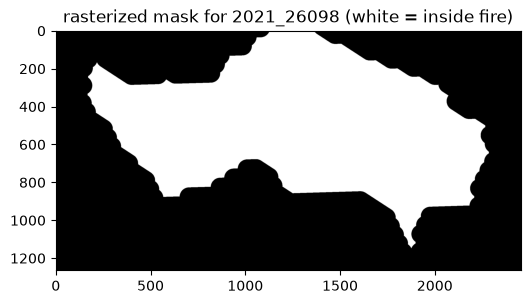

geometry type: Polygon
is_valid: True
number of interior rings (holes): 0


In [37]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(mask_check, cmap="gray")
ax.set_title("rasterized mask for 2021_26098 (white = inside fire)")
plt.savefig("../data/processed/mask_debug.png", dpi=100)
plt.show()

print("geometry type:", inner_check.geometry.iloc[0].geom_type)
print("is_valid:", inner_check.geometry.iloc[0].is_valid)
print("number of interior rings (holes):", len(inner_check.geometry.iloc[0].interiors) if inner_check.geometry.iloc[0].geom_type == "Polygon" else "N/A (multipolygon)")


fixed mask pixel count: 1263937 -> implied area: 12639.37 km2


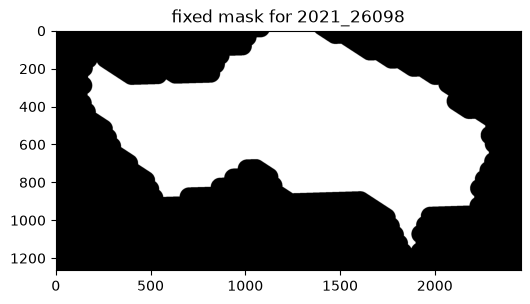

In [39]:
fixed_single_geom = inner_check.geometry.iloc[0].buffer(0)

mask_fixed = rasterize([(fixed_single_geom, 1)], out_shape=own_shape,
                        transform=own_transform, fill=0, dtype="uint8").astype(bool)
print("fixed mask pixel count:", mask_fixed.sum(), "-> implied area:", mask_fixed.sum() * 0.01, "km2")

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(mask_fixed, cmap="gray")
ax.set_title("fixed mask for 2021_26098")
plt.savefig("../data/processed/mask_debug_fixed.png", dpi=100)
plt.show()


In [40]:
raw = inner_burn_area(load_fire("2021_26098"), utm_epsg=own_crs.to_epsg())
print("right after inner_burn_area:")
print("  claimed CRS:", raw.crs)
print("  geometry bounds:", raw.total_bounds)

reproj = raw.to_crs(own_crs)
print("after .to_crs(own_crs):")
print("  claimed CRS:", reproj.crs)
print("  geometry bounds:", reproj.total_bounds)

print("\ntarget tile's own real bounds (in", own_crs, "):")
print(" ", rasterio.transform.array_bounds(*own_shape, own_transform))


right after inner_burn_area:
  claimed CRS: EPSG:4326
  geometry bounds: [-103.08701055   53.1266511  -102.77151919   53.24134012]
after .to_crs(own_crs):
  claimed CRS: PROJCS["WGS 84 / UTM zone 13N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-105],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32613"]]
  geometry bounds: [ 627769.86171295 5888549.37781611  648950.8052574  5901153.27583039]

target tile's own real bounds (in EPSG:32613 ):
  (626090.0, 5887390.0, 650630.0, 5900040.0)


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [41]:
import os
import time
import numpy as np
import pandas as pd
import ee
from rasterio.warp import Resampling

from src.fires import load_fire, derive_fire_params
from src.forest_type import build_landcover, download_landcover, export_landcover, resolve_label
from src.grids import pad_bounds, read_window, reproject_to_grid
from src.height import height_mosaic_for
from src.severity import build_severity, download_severity, export_severity
from src.pipeline import DNBR_DROP_BELOW, SEVERITY_BINS, SEVERITY_LABELS

def attach_height_forest_severity(uid, before_agb, after_agb, mask, tile_crs, tile_transform, tile_shape):
    fire = load_fire(uid)
    lon, lat = fire.geometry.iloc[0].centroid.x, fire.geometry.iloc[0].centroid.y
    bounds = pad_bounds(fire.total_bounds, 0.15)
    row = pd.Series({"uid": uid, "lon": lon, "lat": lat, "start_date": fire["start_date"].iloc[0]})
    params = derive_fire_params(row)
    aoi_ee = ee.Geometry.Rectangle(list(bounds))

    # height
    height_path = height_mosaic_for(lon, lat)
    height_arr, tr_h, crs_h = read_window(height_path, bounds, masked=False)
    height_grid = reproject_to_grid(height_arr.astype("float32"), tr_h, crs_h, tile_shape,
                                      tile_transform, tile_crs, resampling=Resampling.average)

    # severity
    severity_path = f"../data/severity/severity_{uid}.tif"
    if not os.path.exists(severity_path):
        severity_image = build_severity(aoi_ee, *params["pre_fire_window"], *params["post_fire_window"])
        task = export_severity(severity_image, uid, aoi_ee)
        while task.active():
            time.sleep(20)
        severity_path = download_severity(uid)
    dnbr_arr, tr_d, crs_d = read_window(severity_path, bounds, band=1)
    dnbr_grid = reproject_to_grid(np.nan_to_num(dnbr_arr, nan=-9999).astype("float32"), tr_d, crs_d,
                                    tile_shape, tile_transform, tile_crs,
                                    resampling=Resampling.average, src_nodata=-9999)

    # forest type
    landcover_path = f"../data/forest_type/landcover_{uid}.tif"
    if not os.path.exists(landcover_path):
        image = build_landcover(2019)
        task = export_landcover(image, uid, aoi_ee)
        while task.active():
            time.sleep(20)
        landcover_path = download_landcover(uid)
    ft_arr, tr_ft, crs_ft = read_window(landcover_path, bounds, masked=False, band=1)
    ft_grid = reproject_to_grid(ft_arr.astype("float32"), tr_ft, crs_ft, tile_shape,
                                  tile_transform, tile_crs, resampling=Resampling.nearest)
    discrete_arr, tr_disc, crs_disc = read_window(landcover_path, bounds, masked=False, band=2)
    discrete_grid = reproject_to_grid(discrete_arr.astype("float32"), tr_disc, crs_disc, tile_shape,
                                        tile_transform, tile_crs, resampling=Resampling.nearest)

    data = {
        "uid": uid,
        "height": height_grid[mask],
        "dnbr": dnbr_grid[mask],
        "forest_type": ft_grid[mask],
        "forest_type_label": resolve_label(ft_grid[mask], discrete_grid[mask]),
        "before_agb": before_agb[mask],
        "after_agb": after_agb[mask],
    }
    d = pd.DataFrame(data)
    d = d[d["dnbr"] >= DNBR_DROP_BELOW].copy()
    d["severity"] = pd.cut(d["dnbr"], SEVERITY_BINS, labels=SEVERITY_LABELS)
    d["loss"] = 1 - d["after_agb"] / d["before_agb"]
    d["height_class"] = pd.cut(d["height"], [0, 10, 20, 100], labels=["<10m", "10-20m", ">20m"])
    return d


In [43]:
import ee
ee.Authenticate()
ee.Initialize(project="tree-fire-510209")


Enter verification code:  4/1AUn6Hd8QRIkMYNR2YEkq8V4LLfyl04Skwbvo7w4hDhnVedabuPFpPyRG1qs



Successfully saved authorization token.


In [45]:
for cid, uid, before_yq, after_yq, matched_tile in usable:
    fire = load_fire(uid)
    lat = fire.geometry.iloc[0].centroid.y
    in_range = -52 <= lat <= 52
    print(uid, f"lat={lat:.1f}", "usable for height" if in_range else "OUTSIDE GLAD coverage, height unavailable")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26004 lat=54.5 OUTSIDE GLAD coverage, height unavailable


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26098 lat=53.2 OUTSIDE GLAD coverage, height unavailable
2022_92446 lat=-41.5 usable for height


In [46]:
# need this fire's own tile_crs/transform/shape and mask/before_agb/after_agb, since the earlier
# ones in memory are still set to 2021_26098's values from the last debug session
target = [c for c in usable if c[1] == "2022_92446"][0]
cid, uid, before_yq, after_yq, matched_tile = target

before_path = f"../data/artio_tiles/{cid}_{before_yq[0]}_{before_yq[1]}_{matched_tile}.tif"
after_path = f"../data/artio_tiles/{cid}_{after_yq[0]}_{after_yq[1]}_{matched_tile}.tif"

with rasterio.open(before_path) as src:
    before_arr_92446 = src.read(1).astype(float)
    crs_92446, transform_92446, shape_92446 = src.crs, src.transform, before_arr_92446.shape
    nodata_92446 = src.nodata
with rasterio.open(after_path) as src:
    after_arr_92446 = src.read(1).astype(float)

inner_92446 = inner_burn_area(load_fire(uid), utm_epsg=crs_92446.to_epsg()).to_crs(crs_92446)
mask_92446 = rasterize([(g, 1) for g in inner_92446.geometry], out_shape=shape_92446,
                        transform=transform_92446, fill=0, dtype="uint8").astype(bool)

before_agb_92446 = before_arr_92446 / 1.72
after_agb_92446 = after_arr_92446 / 1.72
valid_92446 = mask_92446 & np.isfinite(before_agb_92446) & np.isfinite(after_agb_92446) & (before_agb_92446 > 10)
if nodata_92446 is not None:
    valid_92446 &= (before_arr_92446 != nodata_92446) & (after_arr_92446 != nodata_92446)

print(f"{valid_92446.sum()} valid cells for {uid}")

cell_table_92446 = attach_height_forest_severity(uid, before_agb_92446, after_agb_92446, valid_92446,
                                                   crs_92446, transform_92446, shape_92446)
print(len(cell_table_92446), "cells after dNBR filtering")
print(cell_table_92446[["height", "height_class", "forest_type_label", "severity", "loss"]].describe(include="all"))


185029 valid cells for 2022_92446
179019 cells after dNBR filtering
               height height_class    forest_type_label severity  \
count   179019.000000       178838               179019   179019   
unique            NaN            3                    4        3   
top               NaN       10-20m  evergreen_broadleaf   severe   
freq              NaN        88539               159931   128736   
mean        13.993314          NaN                  NaN      NaN   
std          6.184302          NaN                  NaN      NaN   
min          0.000000          NaN                  NaN      NaN   
25%          9.147578          NaN                  NaN      NaN   
50%         12.700974          NaN                  NaN      NaN   
75%         17.971410          NaN                  NaN      NaN   
max        101.000000          NaN                  NaN      NaN   

                 loss  
count   179019.000000  
unique            NaN  
top               NaN  
freq              N

In [47]:
print("cells with loss < -1:", (cell_table_92446["loss"] < -1).sum(), "of", len(cell_table_92446))
print(cell_table_92446["loss"].describe(percentiles=[0.01, 0.05, 0.95, 0.99]))


cells with loss < -1: 197 of 179019
count    179019.000000
mean          0.446160
std           0.285010
min          -2.711111
1%           -0.444444
5%           -0.090909
95%           0.794118
99%           0.863014
max           1.000000
Name: loss, dtype: float64
